# Chapter 4 · The binomial model: interactive demos

Companion to Chapter 4 of the [IEOR 222 lecture notes](https://gennaroalberto.github.io/ieor222-financial-engineering/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/ieor222-financial-engineering/blob/main/code/notebooks/04-binomial.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/ieor222-financial-engineering#subdirectory=code"

from math import comb
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from ieor222.binomial import (american, european, risk_neutral_probability, stock_paths, stock_tree,
                              tosses, trinomial_price_interval, trinomial_risk_neutral,
                              trinomial_theta_max)
from ieor222.style import COBALT, GOLD, GREY, INK, use_style

use_style()

## 1. Prices and hedge ratios on the tree

Backward induction (Theorem 4.7): at every node the price is the discounted $\mathbb{Q}$-average of the two
successors, $V_n = (q_u V_{n+1}^{H} + q_d V_{n+1}^{T})/(1+r)$, and the hedge ratio $\Delta_n$ is the slope of
the chord between them. Gold boxes are terminal nodes; for an American option, nodes where exercise is optimal
are filled.

Below the tree, the portfolio that starts from $V_0$ and holds $\Delta_n$ shares is run along **all $2^N$
paths** of the full tree. For a European claim it ends exactly at the payoff; for an American claim, the seller's
portfolio stays above the option value $U_n$ at every date (Theorem 4.13(iii)).

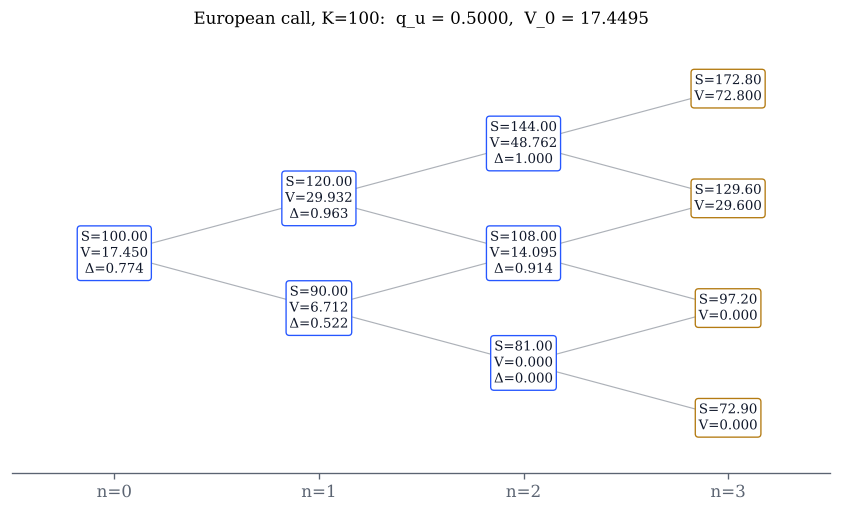

largest |X_N - V_N| over the 8 paths: 2.84e-14


In [2]:
def tree(u=1.2, d=0.9, r=0.05, N=3, K=100.0, kind="call", style="European", S0=100.0):
    if not d < u:
        print("The model needs d < u.")
        return
    if not (0 < d < 1 + r < u):
        side = "d >= 1+r: borrow and buy the stock" if d >= 1 + r else "u <= 1+r: short the stock, invest the cash"
        print(f"No risk-neutral measure, so there is an arbitrage ({side}); Proposition 4.3.")
        return
    q = risk_neutral_probability(u, d, r)
    payoff = (lambda s: np.maximum(s - K, 0.0)) if kind == "call" else (lambda s: np.maximum(K - s, 0.0))
    S = stock_tree(S0, u, d, N)
    if style == "European":
        V, D = european(payoff, S0, u, d, r, N)
        ex = [np.zeros(n + 1, bool) for n in range(N + 1)]
    else:
        V, D, ex = american(payoff, S0, u, d, r, N)
    fig, ax = plt.subplots(figsize=(min(2.2 * (N + 1), 13), 0.75 * (N + 2) + 1))
    fs = 8 if N <= 4 else 6.5
    for n in range(N):
        for j in range(n + 1):
            for jj in (j, j + 1):
                ax.plot([n, n + 1], [2 * j - n, 2 * jj - n - 1], color=GREY, lw=0.7, alpha=0.5, zorder=1)
    for n in range(N + 1):
        for j in range(n + 1):
            txt = f"S={S[n][j]:.2f}\nV={V[n][j]:.3f}" + (f"\nΔ={D[n][j]:.3f}" if n < N else "")
            face = "#DCE4FF" if (ex[n][j] and n < N) else "white"
            ax.text(n, 2 * j - n, txt, ha="center", va="center", fontsize=fs, color=INK, zorder=2,
                    bbox=dict(boxstyle="round,pad=0.25", fc=face, ec=COBALT if n < N else GOLD, lw=0.8))
    ax.set(xticks=range(N + 1), xticklabels=[f"n={n}" for n in range(N + 1)], yticks=[],
           xlim=(-0.5, N + 0.5), ylim=(-N - 1, N + 1),
           title=f"{style} {kind}, K={K:g}:  q_u = {q:.4f},  V_0 = {V[0][0]:.4f}")
    ax.grid(False)
    ax.spines["left"].set_visible(False)
    plt.show()

    # run the hedge along every path of the full tree
    ups = np.concatenate([np.zeros((2**N, 1), dtype=int), np.cumsum(tosses(N), axis=1)], axis=1)
    paths = stock_paths(S0, u, d, N)
    X = np.full(2**N, V[0][0])
    gap = np.inf
    for n in range(N):
        delta = D[n][ups[:, n]]
        X = delta * paths[:, n + 1] + (1 + r) * (X - delta * paths[:, n])
        gap = min(gap, np.min(X - V[n + 1][ups[:, n + 1]]))
    if style == "European":
        print(f"largest |X_N - V_N| over the {2**N} paths: {np.max(np.abs(X - V[N][ups[:, N]])):.2e}")
    else:
        print(f"smallest X_n - U_n over all {2**N} paths and dates: {gap:.2e}  (never negative)")

tree()

In [3]:
# Explore: try a put, switch to American, push d above 1 + r.
interact(tree,
         u=FloatSlider(value=1.2, min=1.01, max=2.0, step=0.01, continuous_update=False, description="u"),
         d=FloatSlider(value=0.9, min=0.3, max=1.2, step=0.01, continuous_update=False, description="d"),
         r=FloatSlider(value=0.05, min=-0.1, max=0.3, step=0.005, continuous_update=False, description="r"),
         N=IntSlider(value=3, min=1, max=6, continuous_update=False, description="N"),
         K=FloatSlider(value=100, min=50, max=150, step=1, continuous_update=False, description="K"),
         kind=Dropdown(options=["call", "put"], value="call", description="claim"),
         style=Dropdown(options=["European", "American"], value="European", description="style"),
         S0=FloatSlider(value=100, min=50, max=150, step=1, continuous_update=False, description="S0"));

## 2. What the real-world probability changes, and what it does not

The price $V_0=\mathbb{E}^{\mathbb{Q}}[(1+r)^{-N}V_N]$ does not involve $p$ (Remark 4.6). The **expected
discounted payoff under $\mathbb{P}$** does: it equals the price only when $p=q_u$, that is, when the stock
earns no risk premium. Above $q_u$ the stock, and a call with it, earn more than $r$ on average.

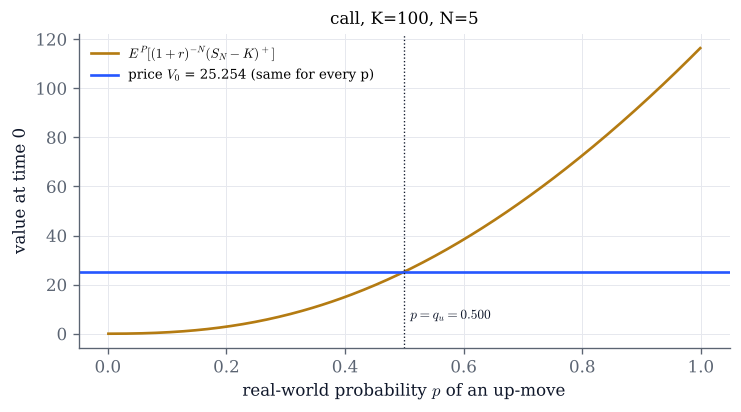

In [4]:
def p_effect(u=1.2, d=0.9, r=0.05, N=5, K=100.0, S0=100.0):
    if not (0 < d < 1 + r < u):
        print("Need d < 1 + r < u.")
        return
    q = risk_neutral_probability(u, d, r)
    k = np.arange(N + 1)
    g = np.maximum(S0 * u**k * d ** (N - k) - K, 0.0)
    binom = np.array([comb(N, j) for j in k], dtype=float)
    ev = lambda p: np.sum(binom * p**k * (1 - p) ** (N - k) * g) / (1 + r) ** N
    ps = np.linspace(0.001, 0.999, 300)
    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.plot(ps, [ev(p) for p in ps], color=GOLD, label="$E^P[(1+r)^{-N}(S_N-K)^+]$")
    ax.axhline(ev(q), color=COBALT, label=f"price $V_0$ = {ev(q):.3f} (same for every p)")
    ax.axvline(q, color=INK, lw=0.8, ls=":")
    ax.text(q + 0.01, 0.05 * ax.get_ylim()[1], f"$p=q_u={q:.3f}$", fontsize=8, color=INK)
    ax.set(xlabel="real-world probability $p$ of an up-move", ylabel="value at time 0",
           title=f"call, K={K:g}, N={N}")
    ax.legend(fontsize=8, loc="upper left")
    plt.show()

p_effect()

In [5]:
interact(p_effect,
         u=FloatSlider(value=1.2, min=1.01, max=2.0, step=0.01, continuous_update=False, description="u"),
         d=FloatSlider(value=0.9, min=0.3, max=1.0, step=0.01, continuous_update=False, description="d"),
         r=FloatSlider(value=0.05, min=0.0, max=0.2, step=0.005, continuous_update=False, description="r"),
         N=IntSlider(value=5, min=1, max=40, continuous_update=False, description="N"),
         K=FloatSlider(value=100, min=50, max=200, step=1, continuous_update=False, description="K"),
         S0=FloatSlider(value=100, min=50, max=150, step=1, continuous_update=False, description="S0"));

## 3. American versus European puts

The American put solves $U_n=\max\big(G_n,\ \mathbb{E}^{\mathbb{Q}}[U_{n+1}\mid\mathcal F_n]/(1+r)\big)$ (Theorem 4.13).
Left: prices at time 0 against $S_0$, with the payoff. Right: the nodes of the tree started at $S_0=K$, marked where
exercise is optimal. Compare with the American call, which is never worth more than the European one when $r\ge0$
(Theorem 4.13(iv)).

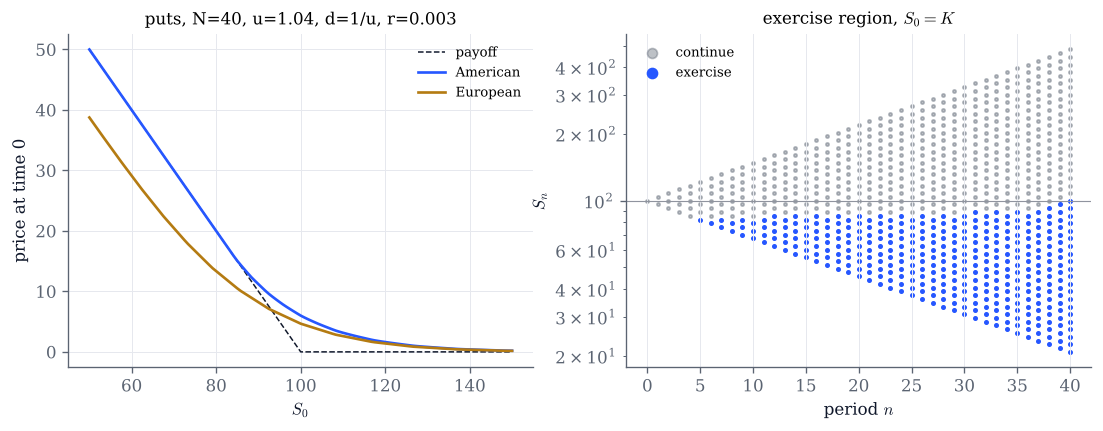

at S0 = K: American 5.9979, European 4.6626, early-exercise premium 1.3353


In [6]:
def american_put(N=40, u=1.04, r=0.003, K=100.0):
    d = 1 / u
    if not (d < 1 + r < u):
        print("Need d < 1 + r < u.")
        return
    put = lambda s: np.maximum(K - s, 0.0)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
    S0s = np.linspace(0.5 * K, 1.5 * K, 121)
    ax.plot(S0s, put(S0s), color=INK, lw=0.9, ls="--", label="payoff")
    ax.plot(S0s, [american(put, s, u, d, r, N)[0][0][0] for s in S0s], color=COBALT, label="American")
    ax.plot(S0s, [european(put, s, u, d, r, N)[0][0][0] for s in S0s], color=GOLD, label="European")
    ax.set(xlabel="$S_0$", ylabel="price at time 0", title=f"puts, N={N}, u={u}, d=1/u, r={r}")
    ax.legend(fontsize=8)
    S = stock_tree(K, u, d, N)
    _, _, ex = american(put, K, u, d, r, N)
    n_all = np.concatenate([np.full(n + 1, n) for n in range(N + 1)])
    s_all, e_all = np.concatenate(S), np.concatenate(ex)
    ax2.scatter(n_all[~e_all], s_all[~e_all], s=4, color=GREY, alpha=0.4, label="continue")
    ax2.scatter(n_all[e_all], s_all[e_all], s=4, color=COBALT, label="exercise")
    ax2.axhline(K, color=INK, lw=0.7, alpha=0.4)
    ax2.set(yscale="log", xlabel="period $n$", ylabel="$S_n$", title="exercise region, $S_0=K$")
    ax2.legend(fontsize=8, markerscale=3)
    plt.show()
    U0 = american(put, K, u, d, r, N)[0][0][0]
    V0 = european(put, K, u, d, r, N)[0][0][0]
    print(f"at S0 = K: American {U0:.4f}, European {V0:.4f}, early-exercise premium {U0 - V0:.4f}")

american_put()

In [7]:
interact(american_put,
         N=IntSlider(value=40, min=2, max=200, continuous_update=False, description="N"),
         u=FloatSlider(value=1.04, min=1.005, max=1.2, step=0.005, readout_format=".3f", continuous_update=False, description="u"),
         r=FloatSlider(value=0.003, min=0.0, max=0.02, step=0.0005, readout_format=".4f", continuous_update=False, description="r"),
         K=FloatSlider(value=100, min=50, max=150, step=1, continuous_update=False, description="K"));

## 4. The trinomial model: an interval of prices

With three states, the risk-neutral measures form a segment $\mathbb{Q}_\theta$, $0<\theta<\theta_{\max}$, where
$\theta$ is the weight of the middle state, and the call price $\mathbb{E}^{\mathbb{Q}_\theta}[(S_1-K)^+]/(1+r)$ moves
along an open interval (Proposition 4.14). Left: the interval as the middle factor $m$ moves from $d$ to $u$.
Right: for the chosen $m$, one price per risk-neutral measure.

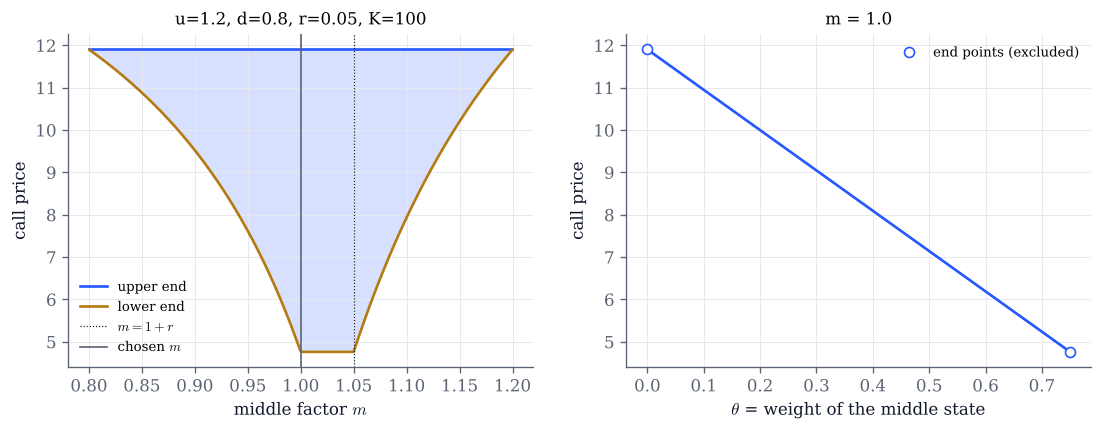

arbitrage-free prices for m = 1.0: (4.7619, 11.9048);  theta_max = 0.7500


In [8]:
def trinomial(u=1.2, d=0.8, r=0.05, K=100.0, m=1.0, S0=100.0):
    if not (0 < d < 1 + r < u) or not (d < m < u):
        print("Need d < 1 + r < u and d < m < u.")
        return
    call = lambda s: np.maximum(s - K, 0.0)
    ms = np.linspace(d + 1e-3 * (u - d), u - 1e-3 * (u - d), 300)
    ends = np.array([trinomial_price_interval(call, S0, u, x, d, r) for x in ms])
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
    ax.fill_between(ms, ends[:, 0], ends[:, 1], color=COBALT, alpha=0.18, lw=0)
    ax.plot(ms, ends[:, 1], color=COBALT, label="upper end")
    ax.plot(ms, ends[:, 0], color=GOLD, label="lower end")
    ax.axvline(1 + r, color=INK, lw=0.7, ls=":", label="$m=1+r$")
    ax.axvline(m, color=GREY, lw=1.0, label="chosen $m$")
    ax.set(xlabel="middle factor $m$", ylabel="call price", title=f"u={u}, d={d}, r={r}, K={K:g}")
    ax.legend(fontsize=8)
    tmax = trinomial_theta_max(u, m, d, r)
    th = np.linspace(0, tmax, 60)
    h = call(np.array([u, m, d]) * S0)
    price = [np.array(trinomial_risk_neutral(u, m, d, r, t)) @ h / (1 + r) for t in th]
    ax2.plot(th, price, color=COBALT)
    ax2.plot([0, tmax], [price[0], price[-1]], "o", mfc="white", mec=COBALT, label="end points (excluded)")
    ax2.set(xlabel="$\\theta$ = weight of the middle state", ylabel="call price", title=f"m = {m}")
    ax2.legend(fontsize=8)
    plt.show()
    lo, hi = trinomial_price_interval(call, S0, u, m, d, r)
    print(f"arbitrage-free prices for m = {m}: ({lo:.4f}, {hi:.4f});  theta_max = {tmax:.4f}")

trinomial()

In [9]:
interact(trinomial,
         u=FloatSlider(value=1.2, min=1.01, max=1.6, step=0.01, continuous_update=False, description="u"),
         d=FloatSlider(value=0.8, min=0.4, max=0.99, step=0.01, continuous_update=False, description="d"),
         r=FloatSlider(value=0.05, min=-0.05, max=0.2, step=0.005, continuous_update=False, description="r"),
         K=FloatSlider(value=100, min=50, max=160, step=1, continuous_update=False, description="K"),
         m=FloatSlider(value=1.0, min=0.41, max=1.59, step=0.01, continuous_update=False, description="m"),
         S0=FloatSlider(value=100, min=50, max=150, step=1, continuous_update=False, description="S0"));

## Things to try

- In section 1, pick a call and move $K$ below $dS_0$ with $N=1$. What does the hedge ratio become, and why
  is the replicating portfolio so simple?
- In section 1, compare the hedge ratios of a European and an American put at nodes where the American put is
  exercised. What does the seller's portfolio look like there?
- In section 2, the two curves cross at $p=q_u$. Can you explain, without computing, why the gold curve is
  increasing in $p$ for a call?
- In section 3, make the tree finer near the money (smaller $u$, larger $N$). Does the early-exercise premium at
  $S_0=K$ stabilise?
- In section 4, move $K$ outside $(dS_0,uS_0)$. Why does the interval collapse to a single price?